# Notebook 01 — EDA and Preprocessing
**Project:** Aircraft Engine Remaining Useful Life (RUL) prediction — NASA C-MAPSS, subset FD001.

**Goal of this notebook:** understand the training data, check its quality, study the target (RUL) and its relationship with the features, then clean the data and save it to `Data/Cleaned/`.

> The original files in `Data/Original/` are only read, never edited.

## 1. Setup

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append("..")                      # lets us import the Helper package
from Helper.helper import load_cmapss, add_rul, CONSTANT_COLUMNS

np.random.seed(42)                          # fixed seed for reproducibility
sns.set_theme(style="whitegrid")

IMAGES = Path("../Images")
IMAGES.mkdir(exist_ok=True)

## 2. Load and inspect the data

In [2]:
df = load_cmapss("../Data/Original/train_FD001.txt")
print("Shape:", df.shape)
df.head()

Shape: (20631, 26)


,engine_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20631 entries, 0 to 20630
Data columns (total 26 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   engine_id  20631 non-null  int64  
 1   cycle      20631 non-null  int64  
 2   setting_1  20631 non-null  float64
 3   setting_2  20631 non-null  float64
 4   setting_3  20631 non-null  float64
 5   sensor_1   20631 non-null  float64
 6   sensor_2   20631 non-null  float64
 7   sensor_3   20631 non-null  float64
 8   sensor_4   20631 non-null  float64
 9   sensor_5   20631 non-null  float64
 10  sensor_6   20631 non-null  float64
 11  sensor_7   20631 non-null  float64
 12  sensor_8   20631 non-null  float64
 13  sensor_9   20631 non-null  float64
 14  sensor_10  20631 non-null  float64
 15  sensor_11  20631 non-null  float64
 16  sensor_12  20631 non-null  float64
 17  sensor_13  20631 non-null  float64
 18  sensor_14  20631 non-null  float64
 19  sensor_15  20631 non-null  float64
 20  sensor_16  20631 

In [4]:
df.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
engine_id,20631.0,51.507,29.228,1.000,26.000,52.000,77.000,100.000
cycle,20631.0,108.808,68.881,1.000,52.000,104.000,156.000,362.000
setting_1,20631.0,-0.000,0.002,-0.009,-0.002,0.000,0.002,0.009
setting_2,20631.0,0.000,0.000,-0.001,-0.000,0.000,0.000,0.001
setting_3,20631.0,100.000,0.000,100.000,100.000,100.000,100.000,100.000
sensor_1,20631.0,518.670,0.000,518.670,518.670,518.670,518.670,518.670
sensor_2,20631.0,642.681,0.500,641.210,642.325,642.640,643.000,644.530
sensor_3,20631.0,1590.523,6.131,1571.040,1586.260,1590.100,1594.380,1616.910
sensor_4,20631.0,1408.934,9.001,1382.250,1402.360,1408.040,1414.555,1441.490
sensor_5,20631.0,14.620,0.000,14.620,14.620,14.620,14.620,14.620


**Finding.** The file has 20,631 rows and 26 columns with no header: `engine_id`, `cycle`, 3 operating settings and 21 sensors. Every column is numeric (4 integer columns and 22 float columns), so no categorical encoding will be needed. Each row is one engine at one operating cycle. We named the columns using the NASA documentation.

## 3. Missing values and duplicates

In [5]:
print("Missing values in total:", int(df.isna().sum().sum()))
print("Fully duplicated rows:", int(df.duplicated().sum()))
print("Duplicated (engine, cycle) pairs:", int(df.duplicated(subset=["engine_id", "cycle"]).sum()))

Missing values in total: 0
Fully duplicated rows: 0
Duplicated (engine, cycle) pairs: 0


**Conclusion.** There are no missing values, no duplicated rows and no repeated (engine, cycle) pairs. Therefore no imputation and no row removal is needed.

## 4. The target: Remaining Useful Life (RUL)
The training engines run until failure, so for every row
`RUL = last recorded cycle of that engine − current cycle`.
An engine has RUL = 0 at its failure cycle.

In [6]:
df = add_rul(df)
df[["engine_id", "cycle", "RUL"]].head()

,engine_id,cycle,RUL
0,1,1,191
1,1,2,190
2,1,3,189
3,1,4,188
4,1,5,187


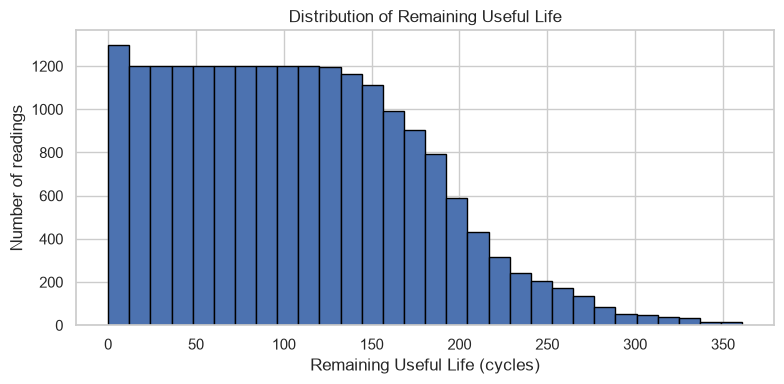

count    20631.0
mean       107.8
std         68.9
min          0.0
25%         51.0
50%        103.0
75%        155.0
max        361.0
Name: RUL, dtype: float64
Skewness: 0.5


In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
df["RUL"].hist(bins=30, edgecolor="black", ax=ax)
ax.set_title("Distribution of Remaining Useful Life")
ax.set_xlabel("Remaining Useful Life (cycles)")
ax.set_ylabel("Number of readings")
fig.tight_layout()
fig.savefig(IMAGES / "rul_distribution.png", dpi=150)
plt.show()
print(df["RUL"].describe().round(1))
print("Skewness:", round(df["RUL"].skew(), 2))

**Finding.** RUL goes from 0 to 361 cycles with a mean of about 108 and a median of 103. The distribution is mildly right-skewed (skewness 0.5): small RUL values are more frequent than large ones, simply because every engine passes through the small values on its way to failure but only the longest-lived engines reach the largest values.

**Decision.** These values are real, not errors, so we keep them in the cleaned data. Whether to cap the *training target* is a modelling question that we answer with evidence in section 9.

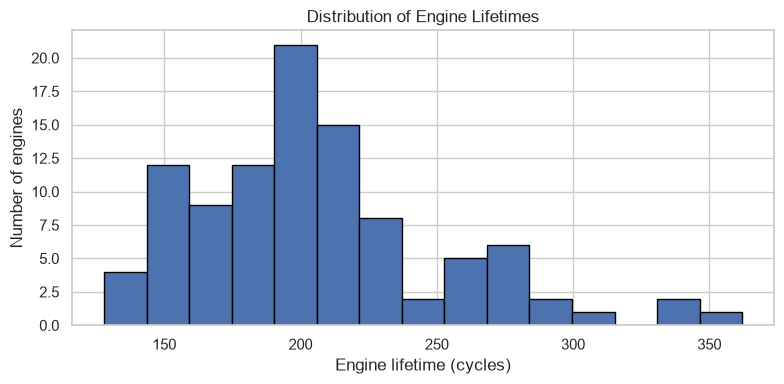

count    100.0
mean     206.3
std       46.3
min      128.0
25%      177.0
50%      199.0
75%      229.2
max      362.0
Name: cycle, dtype: float64


In [8]:
lifetime = df.groupby("engine_id")["cycle"].max()

fig, ax = plt.subplots(figsize=(8, 4))
lifetime.hist(bins=15, edgecolor="black", ax=ax)
ax.set_title("Distribution of Engine Lifetimes")
ax.set_xlabel("Engine lifetime (cycles)")
ax.set_ylabel("Number of engines")
fig.tight_layout()
fig.savefig(IMAGES / "engine_lifetimes.png", dpi=150)
plt.show()
print(lifetime.describe().round(1))

**Finding.** The 100 engines last between 128 and 362 cycles (median 199). Half of them fall between 177 and 229 cycles and a few last much longer. A long life alone is not an error, so all engines are kept. The large spread also means a single cycle count cannot tell us how healthy an engine is — the sensors must carry that information.

## 5. Sensor behaviour over time

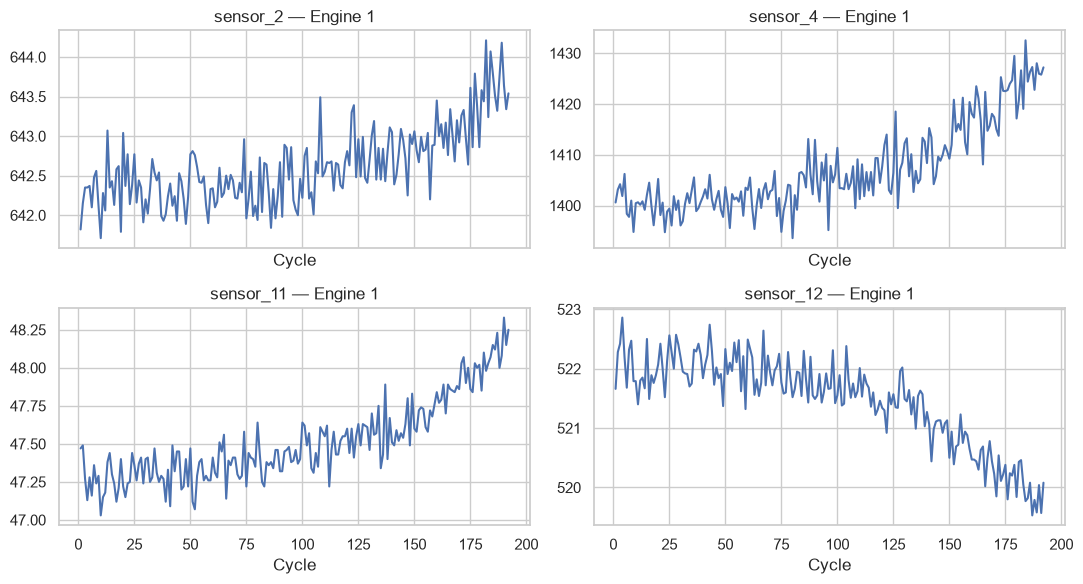

In [9]:
engine1 = df[df["engine_id"] == 1].sort_values("cycle")

fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharex=True)
for ax, col in zip(axes.flatten(), ["sensor_2", "sensor_4", "sensor_11", "sensor_12"]):
    ax.plot(engine1["cycle"], engine1[col])
    ax.set_title(f"{col} — Engine 1")
    ax.set_xlabel("Cycle")
fig.tight_layout()
fig.savefig(IMAGES / "sensor_trends_engine1.png", dpi=150)
plt.show()

**Finding.** For Engine 1, sensor 2 and sensor 4 drift upward as the engine approaches failure, while sensor 11 also rises and sensor 12 falls, all with noticeable cycle-to-cycle noise. This is a degradation signal: the sensors move steadily as the engine wears out, which is what makes RUL predictable from sensor readings.

## 6. Constant features

In [10]:
feature_cols = [c for c in df.columns if c.startswith(("setting_", "sensor_"))]
unique_counts = df[feature_cols].nunique().sort_values()
print(unique_counts.head(10))

constant_cols = unique_counts[unique_counts == 1].index.tolist()
print("\nConstant columns:", constant_cols)
assert sorted(constant_cols) == sorted(CONSTANT_COLUMNS)

sensor_1      1
setting_3     1
sensor_5      1
sensor_10     1
sensor_18     1
sensor_19     1
sensor_16     1
sensor_6      2
sensor_17    13
setting_2    13
dtype: int64

Constant columns: ['sensor_1', 'setting_3', 'sensor_5', 'sensor_10', 'sensor_18', 'sensor_19', 'sensor_16']


**Finding.** Seven columns have exactly one value in every row: `setting_3`, `sensor_1`, `sensor_5`, `sensor_10`, `sensor_16`, `sensor_18`, `sensor_19`. They carry no information about degradation.

**Decision.** Remove them from the cleaned data.

## 7. Outliers

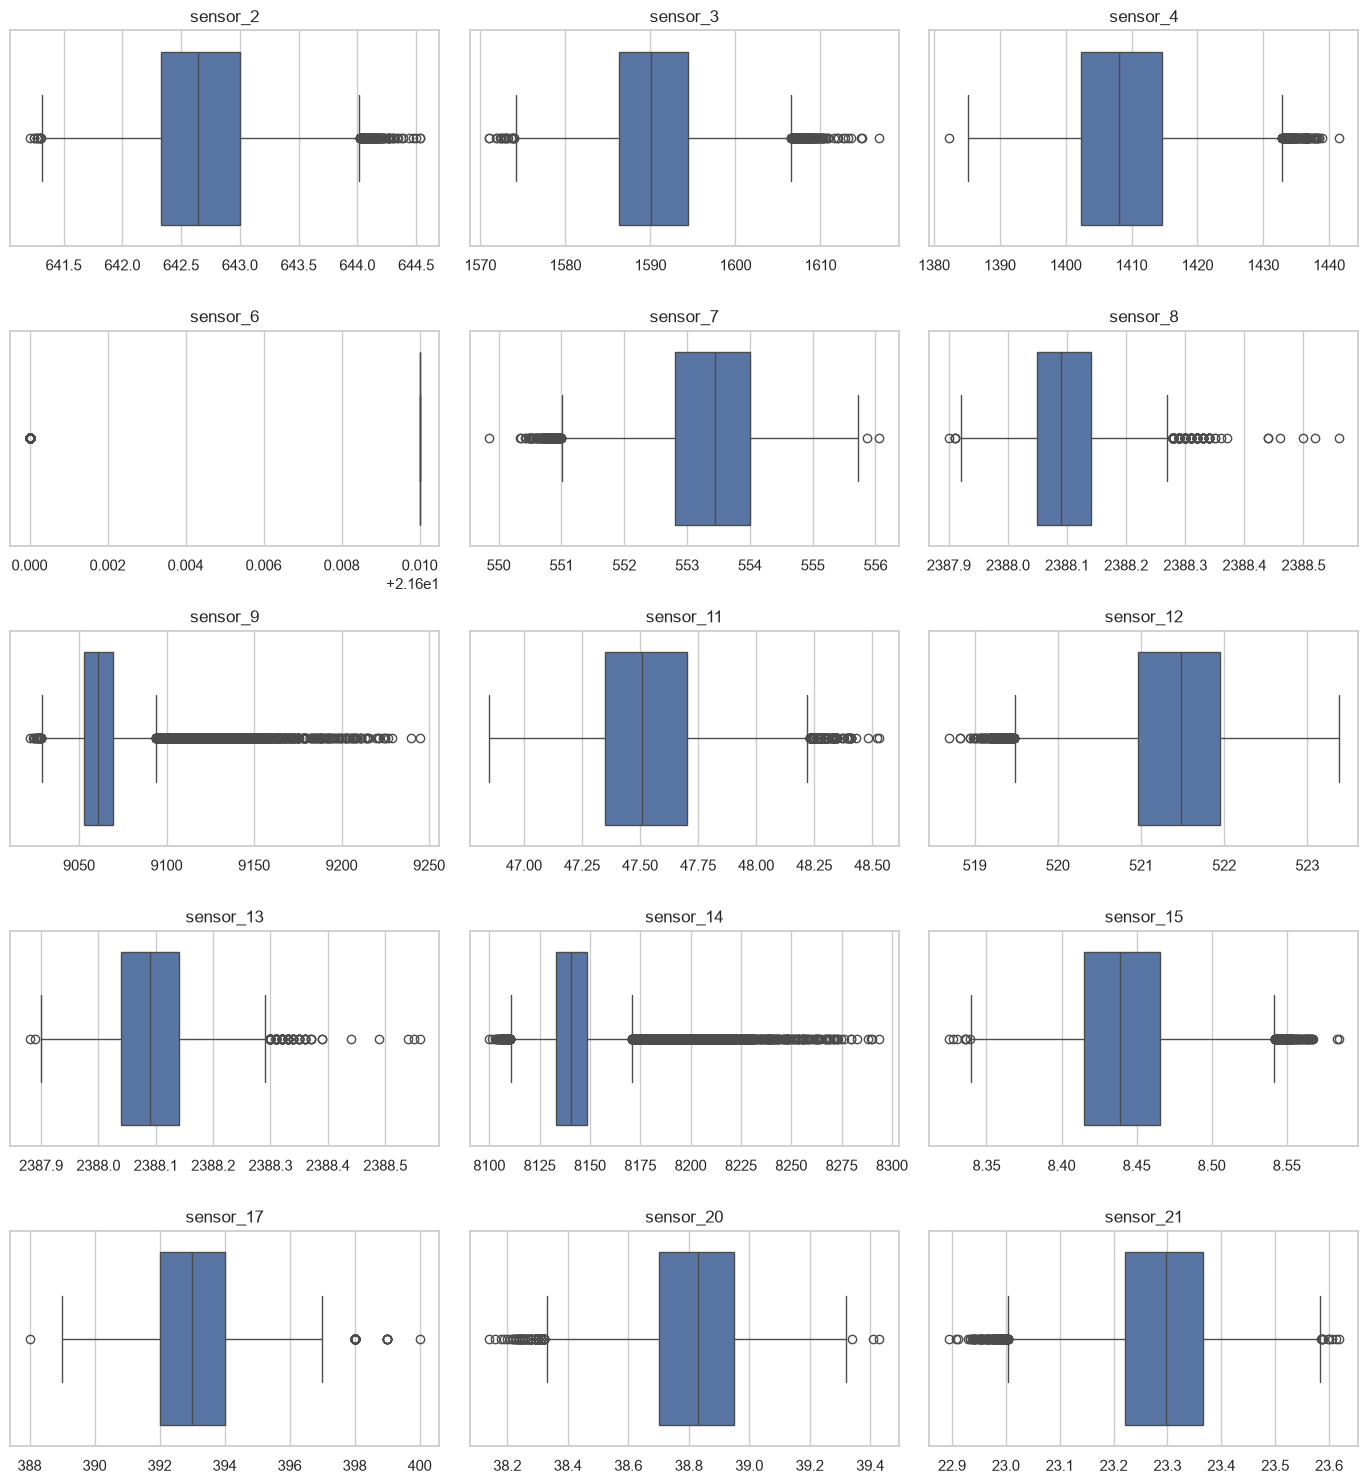

In [11]:
sensor_cols = [c for c in df.columns if c.startswith("sensor_") and df[c].nunique() > 1]

fig, axes = plt.subplots(5, 3, figsize=(14, 15))
for ax, col in zip(axes.flatten(), sensor_cols):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
fig.tight_layout()
fig.savefig(IMAGES / "sensors_boxplot.png", dpi=120)
plt.show()

In [12]:
q1, q3 = df[sensor_cols].quantile(0.25), df[sensor_cols].quantile(0.75)
iqr = q3 - q1
outlier_pct = (((df[sensor_cols] < q1 - 1.5 * iqr) | (df[sensor_cols] > q3 + 1.5 * iqr)).mean() * 100).round(2)
outlier_pct.sort_values(ascending=False).to_frame("% outside 1.5×IQR")

,% outside 1.5×IQR
sensor_9,8.17
sensor_14,7.48
sensor_6,1.97
sensor_8,1.55
sensor_11,0.81
sensor_3,0.80
sensor_13,0.78
sensor_12,0.71
sensor_21,0.66
sensor_2,0.62


**Finding.** Most sensors have few statistical outliers. The highest shares are `sensor_9` (about 8%) and `sensor_14` (about 7.5%); all the others are below about 2%.

**Decision — keep the outliers.** There is no evidence that these readings are sensor errors, and the scatter plots in section 8 show that the extreme sensor values occur together with small RUL, i.e. near the end of an engine's life when degradation is strongest. They therefore hold exactly the information we want to learn from, and removing them would throw away the most informative rows. The tree-based models are also robust to extreme values.

## 8. Relationship between features and RUL

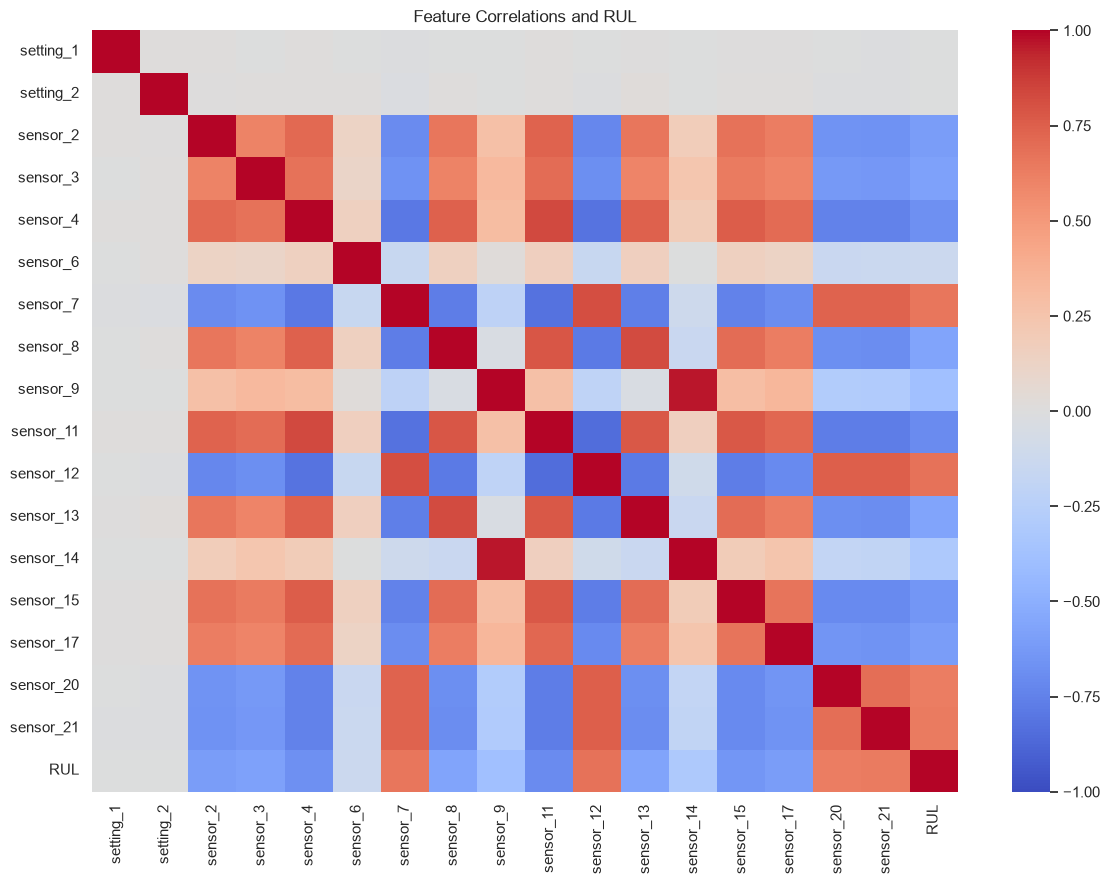

,correlation with RUL
sensor_11,-0.70
sensor_4,-0.68
sensor_15,-0.64
sensor_2,-0.61
sensor_17,-0.61
sensor_3,-0.58
sensor_8,-0.56
sensor_13,-0.56
sensor_9,-0.39
sensor_14,-0.31


In [13]:
plot_cols = [c for c in df.columns if c.startswith(("setting_", "sensor_")) and df[c].nunique() > 1]
corr = df[plot_cols + ["RUL"]].corr()

fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(corr, cmap="coolwarm", vmin=-1, vmax=1, center=0, ax=ax)
ax.set_title("Feature Correlations and RUL")
fig.tight_layout()
fig.savefig(IMAGES / "correlation_heatmap.png", dpi=150)
plt.show()

corr["RUL"].drop("RUL").sort_values().round(2).to_frame("correlation with RUL")

**Finding.**
- Sensors 12, 7, 21 and 20 are positively correlated with RUL (about +0.63 to +0.67); sensors 11, 4, 15, 2, 17, 3, 8 and 13 are negatively correlated (about −0.56 to −0.70).
- `setting_1` and `setting_2` have almost zero linear correlation with RUL. In FD001 there is a single operating condition, so the settings barely vary.
- Some sensors are strongly correlated with each other (for example `sensor_9` and `sensor_14`, correlation about 0.96).

**Decision.** Keep all 17 non-constant features plus `cycle`. The correlated sensors do not hurt tree-based models, and Ridge handles correlated inputs better than plain Linear Regression. Feature usefulness will be judged by cross-validation in Notebook 02, not by correlation alone.

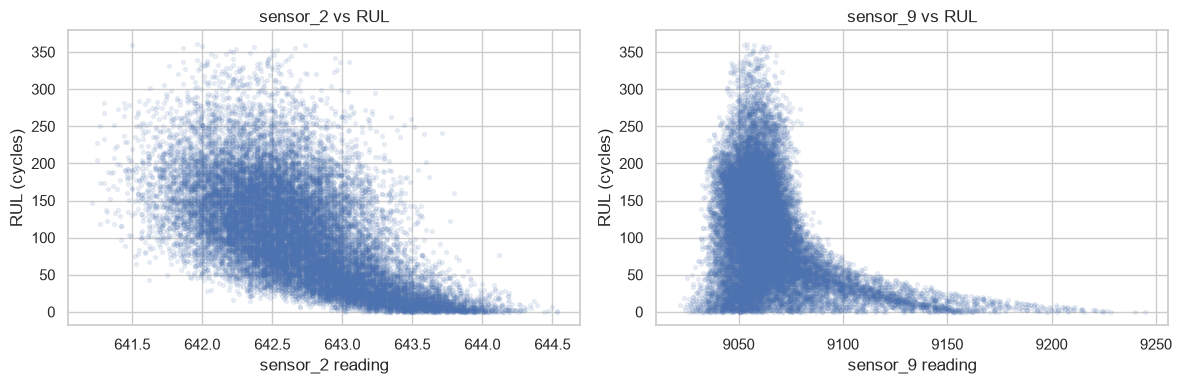

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ["sensor_2", "sensor_9"]):
    ax.scatter(df[col], df["RUL"], alpha=0.1, s=8)
    ax.set_xlabel(f"{col} reading")
    ax.set_ylabel("RUL (cycles)")
    ax.set_title(f"{col} vs RUL")
fig.tight_layout()
fig.savefig(IMAGES / "sensor_vs_rul.png", dpi=150)
plt.show()

**Finding.** Both scatter plots show a clear but **non-linear** and noisy relationship with RUL: the readings change most in the last ~100 cycles and flatten when RUL is large, and sensor 9 mostly shows high readings at small RUL. This is the main reason we expect Random Forest and Gradient Boosting to beat the linear models.

## 9. Is the whole life equally informative? Choosing the training target
Early in an engine's life nothing visibly wears out, so the sensors cannot tell an engine with 300 cycles left from one with 200. The plot averages four strongly related sensors (z-scored) against RUL for all 100 engines.

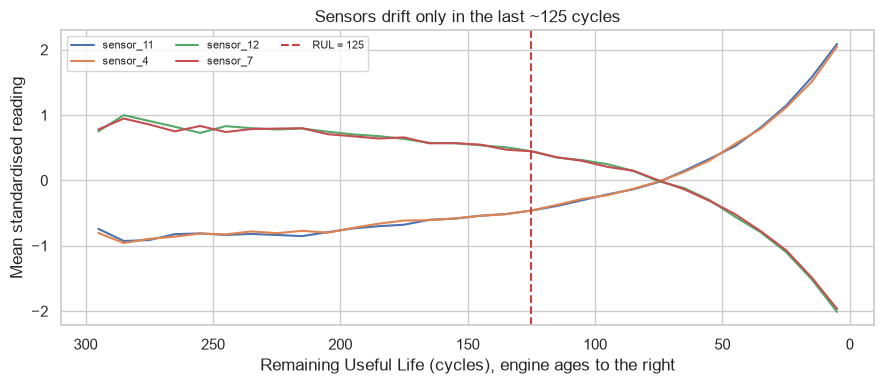

Mean change per 10 cycles when RUL >= 130: 0.053
Mean change per 10 cycles when RUL <= 120: 0.218
Share of training rows with RUL > 125: 0.389


In [15]:
sens = ["sensor_11", "sensor_4", "sensor_12", "sensor_7"]
z = df[sens].apply(lambda s: (s - s.mean()) / s.std())
z["RUL"] = df["RUL"]
curve = z.groupby(pd.cut(z["RUL"], np.arange(0, 301, 10), right=False), observed=True)[sens].mean()
mid = np.array([b.left + 5 for b in curve.index])

fig, ax = plt.subplots(figsize=(9, 4))
for c in sens:
    ax.plot(mid, curve[c], label=c)
ax.axvline(125, color="#ca413f", linestyle="--", label="RUL = 125")
ax.invert_xaxis()
ax.set_xlabel("Remaining Useful Life (cycles), engine ages to the right")
ax.set_ylabel("Mean standardised reading")
ax.set_title("Sensors drift only in the last ~125 cycles")
ax.legend(ncol=3, fontsize=8)
fig.tight_layout()
fig.savefig(IMAGES / "sensor_drift_vs_rul.png", dpi=150)
plt.show()

step = curve.diff().abs().mean(axis=1)
print("Mean change per 10 cycles when RUL >= 130:", round(step[mid >= 130].mean(), 3))
print("Mean change per 10 cycles when RUL <= 120:", round(step[mid <= 120].mean(), 3))
print("Share of training rows with RUL > 125:", round((df["RUL"] > 125).mean(), 3))

**Finding.** The sensors barely move while an engine still has more than about 125 cycles left (average change 0.05 standard deviations per 10 cycles) and then drift about four times faster in the last 120 cycles (0.22). Trying to separate 300 from 200 remaining cycles is therefore guessing, and 39% of the training rows sit in that flat zone.

**Decision.** Keep the real RUL in the cleaned file, but train the models on `min(RUL, 125)`. This is a widely used choice for the C-MAPSS data (a piecewise-linear RUL target). A prediction of 125 therefore means "at least 125 cycles left". Models are always **evaluated against the real RUL** of the NASA test engines, so the gain is not an artefact of the cap. Notebook 02 reports both versions.

## 10. Preprocessing decisions
| Issue found | Decision | Why |
|---|---|---|
| No missing values, no duplicates | No imputation, no row removal | Nothing to fix |
| 7 constant columns | Drop them | They carry no information |
| Statistical outliers | Keep | They come from real end-of-life degradation |
| All columns numeric | No categorical encoding | Nothing to encode |
| Features on very different scales | `StandardScaler` **inside the model pipelines** (Notebook 02) | Scaling must be fitted on the training part of each fold only; scaling the whole file here would leak validation statistics (data leakage). Tree models do not need scaling |
| `engine_id` identifies the engine | Keep in the cleaned file only for grouping; exclude from model inputs | Using it as a feature would not generalise to new engines |
| Rows of one engine are strongly dependent | Split/cross-validate **by engine** (`GroupKFold`) | Random row splits would put the same engine in train and validation |

**Note on scaling.** The brief asks to scale the data. We scale in a pipeline rather than in the saved file on purpose, so the scaler is fitted only on training data and is saved together with each model.

## 11. Build and save the cleaned data

In [16]:
clean_df = (
    df.drop(columns=CONSTANT_COLUMNS)
    .sort_values(["engine_id", "cycle"])
    .reset_index(drop=True)
)

assert {"engine_id", "cycle", "RUL"}.issubset(clean_df.columns)
assert clean_df.isna().sum().sum() == 0
assert not set(CONSTANT_COLUMNS) & set(clean_df.columns)

output_path = Path("../Data/Cleaned/train_FD001_cleaned.csv")
output_path.parent.mkdir(parents=True, exist_ok=True)
clean_df.to_csv(output_path, index=False)

print("Before:", df.shape, "-> After:", clean_df.shape)
print("Saved:", output_path)
clean_df.head()

Before: (20631, 27) -> After: (20631, 20)
Saved: ..\Data\Cleaned\train_FD001_cleaned.csv


,engine_id,cycle,setting_1,setting_2,sensor_2,sensor_3,sensor_4,sensor_6,sensor_7,sensor_8,sensor_9,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_17,sensor_20,sensor_21,RUL
0,1,1,-0.0007,-0.0004,641.82,1589.70,1400.60,21.61,554.36,2388.06,9046.19,47.47,521.66,2388.02,8138.62,8.4195,392,39.06,23.4190,191
1,1,2,0.0019,-0.0003,642.15,1591.82,1403.14,21.61,553.75,2388.04,9044.07,47.49,522.28,2388.07,8131.49,8.4318,392,39.00,23.4236,190
2,1,3,-0.0043,0.0003,642.35,1587.99,1404.20,21.61,554.26,2388.08,9052.94,47.27,522.42,2388.03,8133.23,8.4178,390,38.95,23.3442,189
3,1,4,0.0007,0.0000,642.35,1582.79,1401.87,21.61,554.45,2388.11,9049.48,47.13,522.86,2388.08,8133.83,8.3682,392,38.88,23.3739,188
4,1,5,-0.0019,-0.0002,642.37,1582.85,1406.22,21.61,554.00,2388.06,9055.15,47.28,522.19,2388.04,8133.80,8.4294,393,38.90,23.4044,187


## 12. Summary
- 20,631 rows from 100 engines; no missing values or duplicates.
- Target `RUL` created as *last cycle − current cycle*; range 0–361, mildly right-skewed. Sensors only drift in the last ~125 cycles, so the models are trained on `min(RUL, 125)` (the cleaned file keeps the real RUL).
- 7 constant columns removed → 20 columns saved (`engine_id`, `cycle`, 2 settings, 15 sensors, `RUL`).
- Outliers kept; no encoding needed; scaling is done inside the model pipelines in Notebook 02 to avoid leakage.
- The model input will be 18 features: `cycle` + 2 settings + 15 sensors.
- Cleaned file saved to `Data/Cleaned/train_FD001_cleaned.csv`; plots saved to `Images/`.